<a href="https://colab.research.google.com/github/anupbagale/ssl-brain-parcellation/blob/main/notebooks/01_training_and_label_efficiency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Whole-brain parcellation with SSL pretraining

5-fold cross-validation on 148 OASIS-3 T1w volumes (28 classes), masked-volume pretraining
per fold, and fine-tuning with 10, 25, 50 and 104 labeled scans. Use a GPU runtime.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q "monai-weekly[nibabel, tqdm]"
!nvidia-smi --query-gpu=name,memory.total --format=csv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 49.7 MB/s eta 0:00:00
name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


In [ ]:
import os, glob, json, time, shutil
import numpy as np
import pandas as pd
import torch
import nibabel as nib
import matplotlib.pyplot as plt

from monai.data import PersistentDataset, DataLoader, decollate_batch
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric, HausdorffDistanceMetric
from monai.inferers import sliding_window_inference
from monai.utils import set_determinism
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    NormalizeIntensityd, CropForegroundd, RandCropByPosNegLabeld,
    RandFlipd, RandRotate90d, RandShiftIntensityd, RandScaleIntensityd,
    Lambdad, EnsureTyped, AsDiscrete,
)
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())

torch 2.11.0+cu128 | cuda True


In [ ]:
IMAGE_DIR = '/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder'
LABEL_DIR = '/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder'
ROOT_DIR  = '/content/drive/MyDrive/brain_seg_supervised'
LUT_PATH  = '/content/drive/MyDrive/FreeSurferColorLUT.txt'
CACHE_DIR = '/content/cache'

NUM_CLASSES     = 28
PATCH_SIZE      = (128, 128, 128)
SAMPLES_PER_VOL = 2
BATCH_SIZE      = 2
SEED            = 42

os.makedirs(ROOT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| patch:", PATCH_SIZE, "| classes:", NUM_CLASSES)

device: cuda | patch: (128, 128, 128) | classes: 28


In [ ]:
STD_LABEL_VALUES = np.array([
    0,2,3,4,7,8,10,11,12,13,14,15,16,17,28,31,41,42,43,46,47,49,50,51,52,53,60,63
])
assert len(STD_LABEL_VALUES) == NUM_CLASSES

_LUT = np.zeros(256, dtype=np.int64)          # unmapped FS values -> 0 (background)
for idx, val in enumerate(STD_LABEL_VALUES):
    _LUT[val] = idx

def remap_labels(x):
    if not isinstance(x, torch.Tensor):
        x = torch.as_tensor(np.asarray(x))
    idx = np.clip(x.detach().cpu().numpy().astype(np.int64), 0, 255)
    out = x.clone().float()
    out.copy_(torch.from_numpy(_LUT[idx].astype(np.float32)))
    return out

REGION_NAMES = {}
if os.path.exists(LUT_PATH):
    for line in open(LUT_PATH):
        p = line.split()
        if len(p) >= 5 and p[0].isdigit():
            v = int(p[0])
            if v in STD_LABEL_VALUES:
                REGION_NAMES[int(np.where(STD_LABEL_VALUES == v)[0][0])] = p[1]
CLASS_NAMES = [REGION_NAMES.get(i, f"class_{i}") for i in range(NUM_CLASSES)]
print(f"{NUM_CLASSES} classes, {len(REGION_NAMES)} names loaded")

28 classes, 28 names loaded


In [ ]:
image_files = sorted(glob.glob(f'{IMAGE_DIR}/**/*.nii.gz*', recursive=True))
label_files = sorted(glob.glob(f'{LABEL_DIR}/**/*.nii.gz*', recursive=True))
assert len(image_files) == len(label_files) and len(image_files) > 0
all_files = [{'image': i, 'label': l} for i, l in zip(image_files, label_files)]
print(f"{len(all_files)} image/label pairs")

148 image/label pairs


In [ ]:
for k in range(3):
    ip, lp = all_files[k]['image'], all_files[k]['label']
    im, lb = nib.load(ip), nib.load(lp)
    print(f"[{k}] {os.path.basename(ip)}  img {im.shape}  lbl {lb.shape}  "
          f"spacing {np.round(im.header.get_zooms(),2)}")
    assert im.shape == lb.shape, "shape mismatch -> files NOT paired"
print("sanity check passed")

[0] OAS30021_MR_d0071_anat2.nii.gz  img (256, 256, 256)  lbl (256, 256, 256)  spacing [1. 1. 1.]
[1] OAS30024_MR_d0084_anat2.nii.gz  img (256, 256, 256)  lbl (256, 256, 256)  spacing [1. 1. 1.]
[2] OAS30025_MR_d2298_anat4.nii.gz  img (256, 256, 256)  lbl (256, 256, 256)  spacing [1. 1. 1.]
sanity check passed


In [ ]:
train_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureTyped(keys=["image", "label"], data_type="tensor", track_meta=True),
    Lambdad(keys="label", func=remap_labels),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.0,1.0,1.0), mode=("bilinear","nearest")),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    CropForegroundd(keys=["image","label"], source_key="image", allow_smaller=True,
                    start_coord_key=None, end_coord_key=None),
    RandCropByPosNegLabeld(
        keys=["image","label"], label_key="label", spatial_size=PATCH_SIZE,
        pos=1, neg=1, num_samples=SAMPLES_PER_VOL, image_key="image", image_threshold=0),
    RandScaleIntensityd(keys="image", factors=0.1, prob=0.5),
    RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
    EnsureTyped(keys=["image","label"]),
])

eval_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureTyped(keys=["image", "label"], data_type="tensor", track_meta=True),
    Lambdad(keys="label", func=remap_labels),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.0,1.0,1.0), mode=("bilinear","nearest")),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    EnsureTyped(keys=["image","label"]),
])
print("transforms ready")

transforms ready


/usr/local/lib/python3.12/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [ ]:
FOLDS        = 5
MAX_EPOCHS   = 200
VAL_FRAC     = 0.12
VAL_INTERVAL = 5
LR           = 2e-4

LOCAL_DIR = '/content/cv'
CV_DIR    = os.path.join(ROOT_DIR, 'cv_results')
os.makedirs(LOCAL_DIR, exist_ok=True)
os.makedirs(CV_DIR, exist_ok=True)

post_pred  = AsDiscrete(argmax=True, to_onehot=NUM_CLASSES)
post_label = AsDiscrete(to_onehot=NUM_CLASSES)

import monai
CONFIG = dict(folds=FOLDS, max_epochs=MAX_EPOCHS, patch=list(PATCH_SIZE),
              samples_per_vol=SAMPLES_PER_VOL, batch=BATCH_SIZE, lr=LR,
              val_frac=VAL_FRAC, seed=SEED, num_classes=NUM_CLASSES,
              classes=CLASS_NAMES, monai=monai.__version__, torch=torch.__version__)
json.dump(CONFIG, open(os.path.join(CV_DIR, 'config.json'), 'w'), indent=2)
print(json.dumps({k:v for k,v in CONFIG.items() if k!='classes'}, indent=2))

{
  "folds": 5,
  "max_epochs": 200,
  "patch": [
    128,
    128,
    128
  ],
  "samples_per_vol": 2,
  "batch": 2,
  "lr": 0.0002,
  "val_frac": 0.12,
  "seed": 42,
  "num_classes": 28,
  "monai": "1.7.dev2632",
  "torch": "2.11.0+cu128"
}


In [ ]:
n = len(all_files)
rng = np.random.RandomState(SEED)
perm = rng.permutation(n)
fold_id = np.zeros(n, dtype=int)
for k in range(FOLDS):
    fold_id[perm[k::FOLDS]] = k

folds = []
for k in range(FOLDS):
    test_idx  = np.where(fold_id == k)[0]
    train_all = np.where(fold_id != k)[0]
    train_all = np.random.RandomState(SEED + k).permutation(train_all)
    n_val = max(4, int(VAL_FRAC * len(train_all)))
    folds.append({'fold': k,
                  'val':   [all_files[i] for i in train_all[:n_val]],
                  'train': [all_files[i] for i in train_all[n_val:]],
                  'test':  [all_files[i] for i in test_idx]})
    print(f"fold {k}: train={len(folds[-1]['train'])} val={len(folds[-1]['val'])} "
          f"test={len(folds[-1]['test'])}")

assert sum(len(f['test']) for f in folds) == n
json.dump([{'fold': f['fold'], **{s: [d['image'] for d in f[s]] for s in ('train','val','test')}}
           for f in folds], open(os.path.join(CV_DIR, 'folds.json'), 'w'), indent=2)
print("\nfolds saved to folds.json")

fold 0: train=104 val=14 test=30
fold 1: train=104 val=14 test=30
fold 2: train=104 val=14 test=30
fold 3: train=105 val=14 test=29
fold 4: train=105 val=14 test=29

folds saved to folds.json


In [ ]:
def safe_copy(src, dst):
    try:
        shutil.copyfile(src, dst); return True
    except Exception as e:
        print(f"   [warn] Drive copy failed ({type(e).__name__})"); return False

def build_model():
    return UNet(spatial_dims=3, in_channels=1, out_channels=NUM_CLASSES,
                channels=(32,64,128,256,320), strides=(2,2,2,2),
                num_res_units=2, norm=Norm.INSTANCE, dropout=0.1).to(device)

def run_fold(f):
    k = f['fold']; tag = f"fold{k}"
    print(f"\n{'='*60}\nFOLD {k}\n{'='*60}")

    tr_ld = DataLoader(PersistentDataset(f['train'], train_transforms, f'{CACHE_DIR}/{tag}_tr'),
                       batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    va_ld = DataLoader(PersistentDataset(f['val'], eval_transforms, f'{CACHE_DIR}/{tag}_va'),
                       batch_size=1, shuffle=False, num_workers=2)

    model = build_model()
    loss_fn   = DiceCELoss(to_onehot_y=True, softmax=True, include_background=False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)
    scaler    = torch.amp.GradScaler('cuda')
    dmean = DiceMetric(include_background=False, reduction="mean")

    local_best = os.path.join(LOCAL_DIR, f'best_{tag}.pth')
    local_ck   = os.path.join(LOCAL_DIR, f'ckpt_{tag}.pth')
    drive_best = os.path.join(CV_DIR,    f'best_{tag}.pth')

    start_epoch, best_metric, best_epoch = 0, -1.0, -1
    hist = {'loss': [], 'val_dice': []}
    if os.path.exists(local_ck):
        ck = torch.load(local_ck, map_location=device)
        model.load_state_dict(ck['model_state_dict'])
        optimizer.load_state_dict(ck['optimizer_state_dict'])
        scheduler.load_state_dict(ck['scheduler_state_dict'])
        start_epoch, best_metric, best_epoch = ck['epoch'], ck['best_metric'], ck['best_epoch']
        hist = ck.get('history', hist)
        print(f"resumed @ epoch {start_epoch}")

    for epoch in range(start_epoch, MAX_EPOCHS):
        model.train(); ep_loss, steps, t0 = 0.0, 0, time.time()
        for b in tr_ld:
            x, y = b['image'].to(device), b['label'].to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda'):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            ep_loss += loss.item(); steps += 1
        scheduler.step(); ep_loss /= max(steps,1); hist['loss'].append(ep_loss)
        if (epoch+1) % 10 == 0 or epoch == 0:
            print(f"  [f{k}] epoch {epoch+1}/{MAX_EPOCHS}  loss {ep_loss:.4f}  ({time.time()-t0:.0f}s)")

        if (epoch+1) % VAL_INTERVAL == 0:
            model.eval()
            with torch.no_grad(), torch.amp.autocast('cuda'):
                for vb in va_ld:
                    vo = sliding_window_inference(vb['image'].to(device), PATCH_SIZE, 2, model, overlap=0.5)
                    vo = [post_pred(i) for i in decollate_batch(vo)]
                    vy = [post_label(i) for i in decollate_batch(vb['label'].to(device))]
                    dmean(y_pred=vo, y=vy)
            m = dmean.aggregate().item(); dmean.reset()
            hist['val_dice'].append((epoch+1, m))
            if m > best_metric:
                best_metric, best_epoch = m, epoch+1
                torch.save({'model_state_dict': model.state_dict(), 'epoch': best_epoch,
                            'best_metric': best_metric}, local_best)
                safe_copy(local_best, drive_best)
                print(f"  [f{k}] epoch {epoch+1}  VAL {m:.4f}  * best")

        torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scheduler_state_dict': scheduler.state_dict(),
                    'best_metric': best_metric, 'best_epoch': best_epoch,
                    'history': hist}, local_ck)

    # --- test on this fold's untouched held-out subjects ---
    te_ld = DataLoader(PersistentDataset(f['test'], eval_transforms, f'{CACHE_DIR}/{tag}_te'),
                       batch_size=1, shuffle=False, num_workers=2)
    model.load_state_dict(torch.load(local_best, map_location=device)['model_state_dict'])
    model.eval()

    dcls = DiceMetric(include_background=False, reduction="mean_batch")
    hdm  = HausdorffDistanceMetric(include_background=False, percentile=95, reduction="mean_batch")
    subj, hd_ok = [], True
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for tb in te_ld:
            to = sliding_window_inference(tb['image'].to(device), PATCH_SIZE, 2, model, overlap=0.5)
            to = [post_pred(i) for i in decollate_batch(to)]
            ty = [post_label(i) for i in decollate_batch(tb['label'].to(device))]
            subj.append(float(DiceMetric(include_background=False, reduction="mean")(y_pred=to, y=ty).mean()))
            dcls(y_pred=to, y=ty)
            if hd_ok:
                try:
                    # HD95 on CPU: the GPU path routes through cupy, whose kernel
                    # compilation fails in this Colab image
                    hdm(y_pred=[t.cpu().float() for t in to], y=[t.cpu().float() for t in ty])
                except Exception as e:
                    print(f"   [warn] HD95 unavailable ({type(e).__name__}) - Dice only")
                    hd_ok = False

    pc_d = dcls.aggregate().cpu().numpy()
    if hd_ok:
        pc_h = hdm.aggregate().cpu().numpy()
        pc_h = np.where(np.isfinite(pc_h), pc_h, np.nan)
    else:
        pc_h = np.full_like(pc_d, np.nan)

    res = {'fold': k, 'best_epoch': best_epoch, 'val_dice': best_metric,
           'test_mean_dice': float(np.mean(subj)), 'test_std_dice': float(np.std(subj)),
           'per_subject': subj, 'per_class_dice': pc_d.tolist(),
           'per_class_hd95': pc_h.tolist(), 'history': hist}
    json.dump(res, open(os.path.join(CV_DIR, f'results_{tag}.json'), 'w'), indent=2)
    print(f"  [f{k}] TEST {np.mean(subj):.4f} +/- {np.std(subj):.4f}")
    return res

print("run_fold defined")

run_fold defined


In [ ]:
all_res = []
for f in folds:
    rp = os.path.join(CV_DIR, f"results_fold{f['fold']}.json")
    if os.path.exists(rp):
        all_res.append(json.load(open(rp)))
        print(f"fold {f['fold']} already done - skipping")
        continue
    all_res.append(run_fold(f))
print("\nALL FOLDS COMPLETE")


FOLD 0
resumed @ epoch 200


/usr/local/lib/python3.12/dist-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


  [f0] TEST 0.7999 +/- 0.0592

FOLD 1
  [f1] epoch 1/200  loss 2.8000  (151s)
  [f1] epoch 5  VAL 0.2419  * best
  [f1] epoch 10/200  loss 0.6491  (12s)
  [f1] epoch 10  VAL 0.5912  * best
  [f1] epoch 15  VAL 0.6666  * best
  [f1] epoch 20/200  loss 0.4248  (11s)
  [f1] epoch 20  VAL 0.7466  * best
  [f1] epoch 30/200  loss 0.3906  (11s)
  [f1] epoch 35  VAL 0.7877  * best
  [f1] epoch 40/200  loss 0.3625  (11s)
  [f1] epoch 50/200  loss 0.3378  (11s)
  [f1] epoch 60/200  loss 0.3290  (11s)
  [f1] epoch 65  VAL 0.8007  * best
  [f1] epoch 70/200  loss 0.3406  (11s)
  [f1] epoch 80/200  loss 0.3149  (11s)
  [f1] epoch 90/200  loss 0.3128  (11s)
  [f1] epoch 100/200  loss 0.3018  (11s)
  [f1] epoch 110/200  loss 0.2958  (11s)
  [f1] epoch 120/200  loss 0.2965  (11s)
  [f1] epoch 130/200  loss 0.2921  (11s)
  [f1] epoch 140/200  loss 0.2807  (11s)
  [f1] epoch 150/200  loss 0.2921  (11s)
  [f1] epoch 160/200  loss 0.2747  (11s)
  [f1] epoch 170/200  loss 0.2859  (11s)
  [f1] epoch 180/20

In [ ]:
md = [r['test_mean_dice'] for r in all_res]
print(f"=== {FOLDS}-FOLD CV (n={len(all_files)} subjects) ===")
for r in all_res:
    print(f"  fold {r['fold']}: {r['test_mean_dice']:.4f} +/- {r['test_std_dice']:.4f} "
          f"(best epoch {r['best_epoch']})")
print(f"\nOVERALL: {np.mean(md):.4f} +/- {np.std(md):.4f}")

pc = np.vstack([r['per_class_dice'] for r in all_res])
ph = np.vstack([r['per_class_hd95'] for r in all_res])
df = pd.DataFrame({'region': [CLASS_NAMES[i+1] for i in range(pc.shape[1])],
                   'dice_mean': np.round(pc.mean(0),4),
                   'dice_std':  np.round(pc.std(0),4),
                   'hd95_mean': np.round(np.nanmean(ph,0),3)}
                 ).sort_values('dice_mean', ascending=False)
df.to_csv(os.path.join(CV_DIR, 'cv_per_region.csv'), index=False)
print(f"\n{df.to_string(index=False)}")

=== 5-FOLD CV (n=148 subjects) ===
  fold 0: 0.7999 +/- 0.0592 (best epoch 140)
  fold 1: 0.8073 +/- 0.0233 (best epoch 65)
  fold 2: 0.8163 +/- 0.0198 (best epoch 115)
  fold 3: 0.7797 +/- 0.0623 (best epoch 95)
  fold 4: 0.7883 +/- 0.0358 (best epoch 150)

OVERALL: 0.7983 +/- 0.0131

                       region  dice_mean  dice_std  hd95_mean
                   Brain-Stem     0.9082    0.0117     57.555
      Right-Cerebellum-Cortex     0.8745    0.0130     39.175
               Right-Thalamus     0.8710    0.0164     18.750
      Right-Lateral-Ventricle     0.8682    0.0356      4.624
Right-Cerebellum-White-Matter     0.8668    0.0139     29.730
 Left-Cerebellum-White-Matter     0.8660    0.0185     25.566
       Left-Cerebellum-Cortex     0.8640    0.0185     19.801
            Right-Hippocampus     0.8487    0.0329     46.143
       Left-Lateral-Ventricle     0.8441    0.0280      6.687
             Left-Hippocampus     0.8316    0.0183     37.986
              Right-VentralDC  

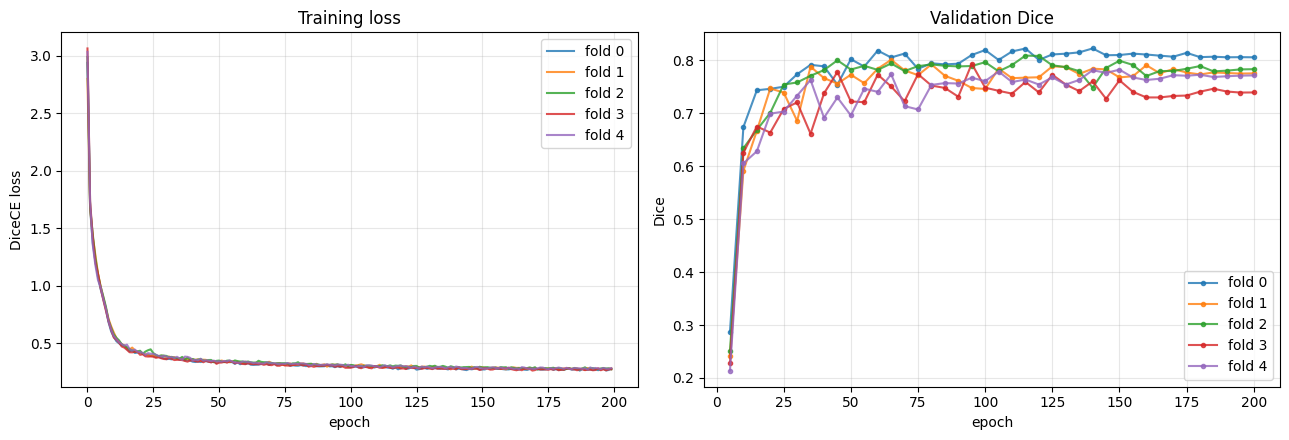

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for r in all_res:
    ax[0].plot(r['history']['loss'], label=f"fold {r['fold']}", alpha=.8)
    ep, dc = zip(*r['history']['val_dice'])
    ax[1].plot(ep, dc, marker='o', ms=3, label=f"fold {r['fold']}", alpha=.8)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('DiceCE loss'); ax[0].set_title('Training loss'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('Dice'); ax[1].set_title('Validation Dice'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CV_DIR,'cv_curves.png'), dpi=150); plt.show()

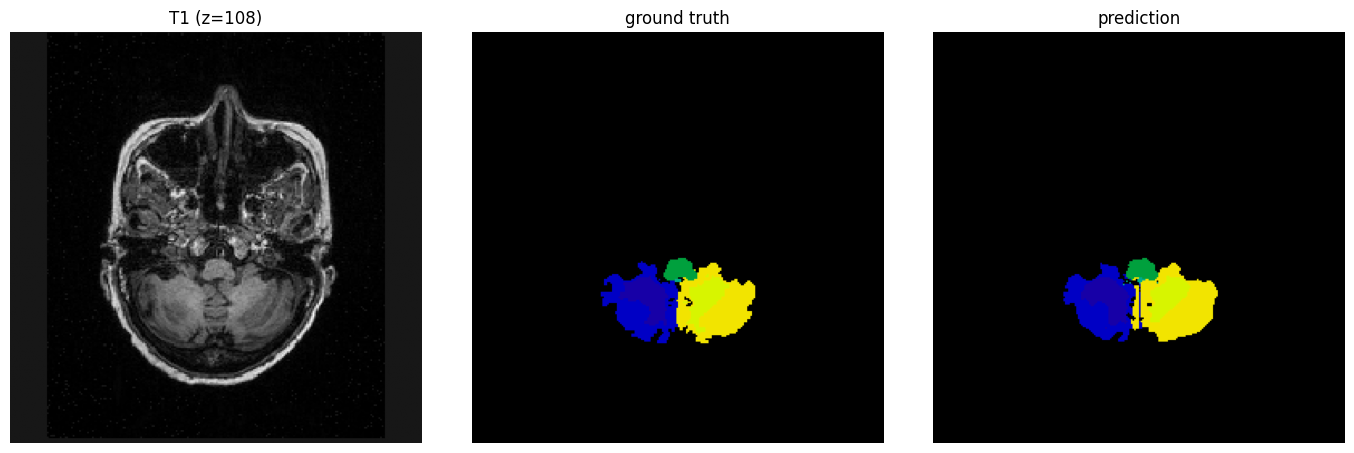

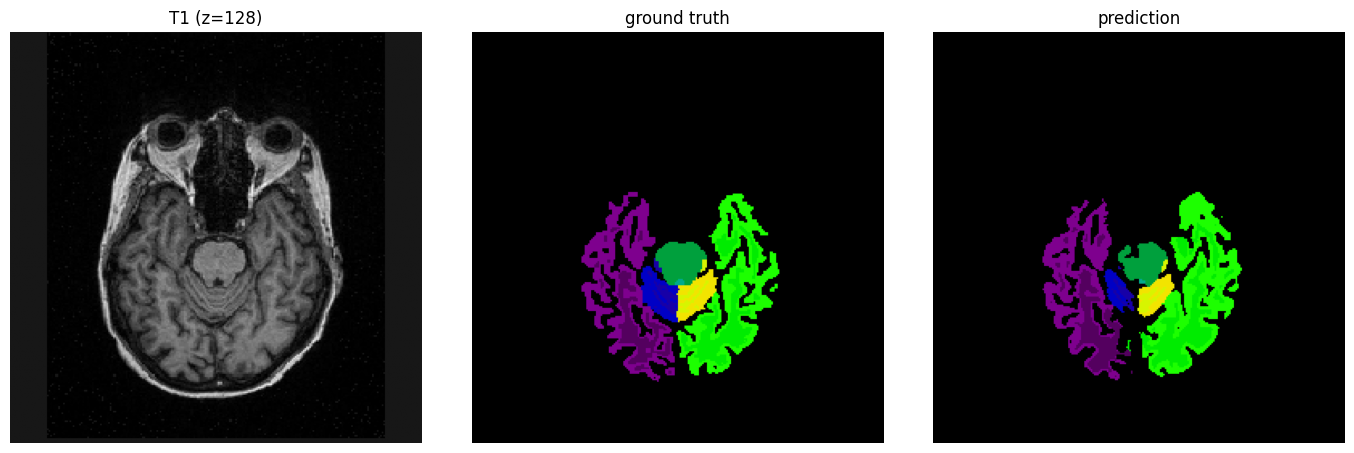

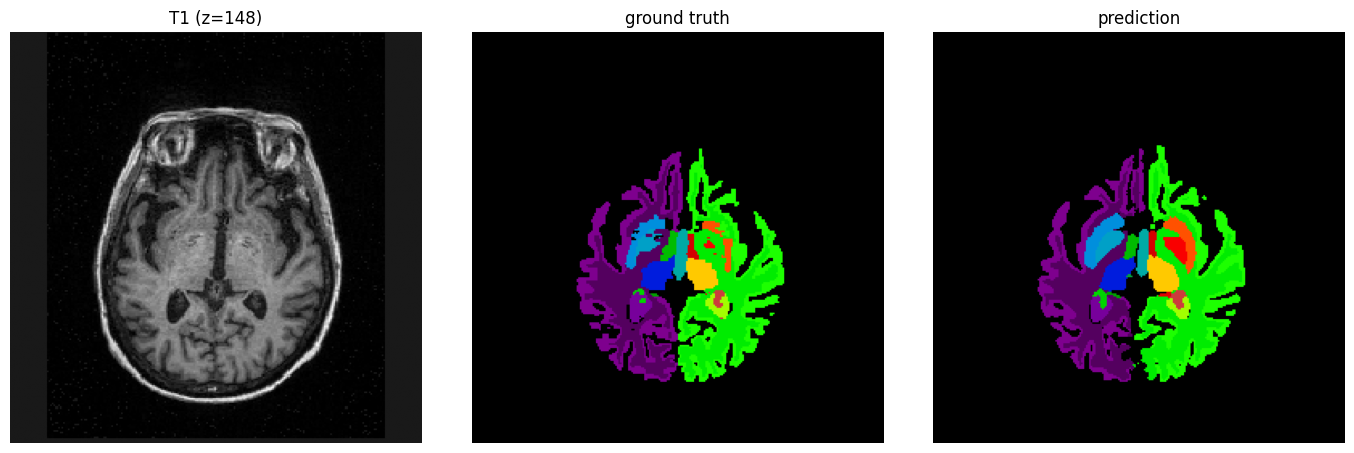

In [ ]:
best_fold = int(np.argmax(md))
model = build_model()
model.load_state_dict(torch.load(os.path.join(LOCAL_DIR, f'best_fold{best_fold}.pth'),
                                 map_location=device)['model_state_dict'])
model.eval()
te_ld = DataLoader(PersistentDataset(folds[best_fold]['test'], eval_transforms,
                   f'{CACHE_DIR}/fold{best_fold}_te'), batch_size=1, num_workers=2)
tb = next(iter(te_ld))
with torch.no_grad(), torch.amp.autocast('cuda'):
    lg = sliding_window_inference(tb['image'].to(device), PATCH_SIZE, 2, model, overlap=0.5)
pred = torch.argmax(lg, 1)[0].cpu().numpy()
gt   = tb['label'][0,0].numpy(); img = tb['image'][0,0].numpy()

for z in [img.shape[2]//2 - 20, img.shape[2]//2, img.shape[2]//2 + 20]:
    fig, ax = plt.subplots(1,3, figsize=(14,4.5))
    ax[0].imshow(img[:,:,z].T, cmap='gray', origin='lower'); ax[0].set_title(f'T1 (z={z})')
    ax[1].imshow(gt[:,:,z].T, cmap='nipy_spectral', origin='lower', vmin=0, vmax=NUM_CLASSES); ax[1].set_title('ground truth')
    ax[2].imshow(pred[:,:,z].T, cmap='nipy_spectral', origin='lower', vmin=0, vmax=NUM_CLASSES); ax[2].set_title('prediction')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(CV_DIR, f'qualitative_z{z}.png'), dpi=150); plt.show()

In [ ]:
SSL_EPOCHS  = 150
SSL_LR      = 1e-4
SSL_SAMPLES = 2
SSL_BATCH   = 2
MASK_BLOCKS = 40
MASK_MIN, MASK_MAX = 0.15, 0.40

SSL_DIR = os.path.join(ROOT_DIR, 'ssl_results')
os.makedirs(SSL_DIR, exist_ok=True)

json.dump(dict(ssl_epochs=SSL_EPOCHS, ssl_lr=SSL_LR, patch=list(PATCH_SIZE),
               mask_blocks=MASK_BLOCKS, mask_range=[MASK_MIN, MASK_MAX],
               note='in-domain masked-volume reconstruction, per-fold, train subjects only'),
          open(os.path.join(SSL_DIR, 'ssl_config.json'), 'w'), indent=2)
print("SSL config saved to", SSL_DIR)

SSL config saved to /content/drive/MyDrive/brain_seg_supervised/ssl_results


In [ ]:
from monai.transforms import RandSpatialCropSamplesd

def random_cuboid_mask(shape, n_blocks=MASK_BLOCKS, min_f=MASK_MIN, max_f=MASK_MAX):
    """1 = masked/hidden, 0 = visible. ~45% coverage with these defaults."""
    D, H, W = shape
    m = np.zeros(shape, dtype=np.float32)
    for _ in range(n_blocks):
        d = int(D*np.random.uniform(min_f, max_f))
        h = int(H*np.random.uniform(min_f, max_f))
        w = int(W*np.random.uniform(min_f, max_f))
        z = np.random.randint(0, max(1, D-d))
        y = np.random.randint(0, max(1, H-h))
        x = np.random.randint(0, max(1, W-w))
        m[z:z+d, y:y+h, x:x+w] = 1.0
    return m

ssl_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureTyped(keys=["image"], data_type="tensor", track_meta=True),
    EnsureChannelFirstd(keys=["image"]),
    Orientationd(keys=["image"], axcodes="RAS"),
    Spacingd(keys=["image"], pixdim=(1.0,1.0,1.0), mode="bilinear"),
    NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
    CropForegroundd(keys=["image"], source_key="image", allow_smaller=True,
                    start_coord_key=None, end_coord_key=None),
    RandSpatialCropSamplesd(keys=["image"], roi_size=PATCH_SIZE,
                            num_samples=SSL_SAMPLES, random_size=False),
    RandScaleIntensityd(keys="image", factors=0.1, prob=0.5),
    RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
    EnsureTyped(keys=["image"]),
])

# sanity check on the mask coverage
_m = random_cuboid_mask(PATCH_SIZE)
print(f"ssl transforms ready | masked fraction ~{_m.mean():.3f}")

ssl transforms ready | masked fraction ~0.458


In [ ]:
def pretrain_fold(f):
    """Masked-reconstruction pretraining on this fold's TRAIN subjects only.
    Val/test subjects are not used."""
    k = f['fold']; tag = f"fold{k}"
    out_path  = os.path.join(LOCAL_DIR, f'ssl_{tag}.pth')
    drive_out = os.path.join(SSL_DIR,   f'ssl_{tag}.pth')

    if os.path.exists(drive_out) and not os.path.exists(out_path):
        safe_copy(drive_out, out_path)
    if os.path.exists(out_path):
        print(f"SSL fold {k} already done - skipping")
        return out_path

    print(f"\n{'='*60}\nSSL PRETRAIN FOLD {k}  ({len(f['train'])} unlabeled volumes)\n{'='*60}")
    files = [{'image': d['image']} for d in f['train']]
    ld = DataLoader(PersistentDataset(files, ssl_transforms, f'{CACHE_DIR}/{tag}_ssl'),
                    batch_size=SSL_BATCH, shuffle=True, num_workers=2, pin_memory=True)

    model = UNet(spatial_dims=3, in_channels=1, out_channels=1,
                 channels=(32,64,128,256,320), strides=(2,2,2,2),
                 num_res_units=2, norm=Norm.INSTANCE, dropout=0.1).to(device)
    opt    = torch.optim.AdamW(model.parameters(), lr=SSL_LR, weight_decay=1e-5)
    sch    = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=SSL_EPOCHS)
    scaler = torch.amp.GradScaler('cuda')

    for epoch in range(SSL_EPOCHS):
        model.train(); tot, n, t0 = 0.0, 0, time.time()
        for b in ld:
            x = b['image'].to(device)
            masks = torch.stack([torch.from_numpy(random_cuboid_mask(tuple(x.shape[2:])))
                                 for _ in range(x.shape[0])]).unsqueeze(1).to(device)
            x_masked = x * (1 - masks)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda'):
                rec = model(x_masked)
                # loss on masked voxels only
                loss = (torch.abs(rec - x) * masks).sum() / (masks.sum() + 1e-8)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); n += 1
        sch.step()
        if (epoch+1) % 10 == 0 or epoch == 0:
            print(f"  [ssl f{k}] epoch {epoch+1}/{SSL_EPOCHS}  L1 {tot/max(n,1):.4f}  ({time.time()-t0:.0f}s)")

    torch.save({'model_state_dict': model.state_dict(), 'epochs': SSL_EPOCHS}, out_path)
    safe_copy(out_path, drive_out)
    print(f"  [ssl f{k}] saved")
    return out_path

print("pretrain_fold defined")

pretrain_fold defined


In [ ]:
for f in folds:
    pretrain_fold(f)
print("\nALL SSL PRETRAINING COMPLETE")

SSL fold 0 already done - skipping
SSL fold 1 already done - skipping
SSL fold 2 already done - skipping
SSL fold 3 already done - skipping
SSL fold 4 already done - skipping

ALL SSL PRETRAINING COMPLETE


In [ ]:
def load_pretrained_encoder(seg_model, ssl_path):
    """Transfer everything except the final output layer (1 channel vs NUM_CLASSES)."""
    sd_ssl = torch.load(ssl_path, map_location=device)['model_state_dict']
    sd_seg = seg_model.state_dict()
    ok = {k: v for k, v in sd_ssl.items() if k in sd_seg and v.shape == sd_seg[k].shape}
    missing, _ = seg_model.load_state_dict(ok, strict=False)
    n_t = sum(sd_seg[k].numel() for k in ok)
    n_a = sum(v.numel() for v in sd_seg.values())
    print(f"   transferred {len(ok)}/{len(sd_seg)} tensors = {100*n_t/n_a:.1f}% of weights "
          f"({len(missing)} reinitialized)")
    return seg_model


def run_fold_ssl(f, n_labeled=None, pretrained=True):
    """Fine-tune with or without SSL init. n_labeled=None uses all training subjects."""
    k = f['fold']
    train_sub = f['train'] if n_labeled is None else f['train'][:n_labeled]
    tag = f"fold{k}_{'ssl' if pretrained else 'scratch'}_n{len(train_sub)}"
    res_path = os.path.join(SSL_DIR, f'results_{tag}.json')
    if os.path.exists(res_path):
        print(f"{tag} already done - skipping")
        return json.load(open(res_path))

    print(f"\n--- {tag} ({len(train_sub)} labeled subjects) ---")
    tr_ld = DataLoader(PersistentDataset(train_sub, train_transforms, f'{CACHE_DIR}/{tag}_tr'),
                       batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    va_ld = DataLoader(PersistentDataset(f['val'], eval_transforms, f'{CACHE_DIR}/fold{k}_va'),
                       batch_size=1, shuffle=False, num_workers=2)

    model = build_model()
    if pretrained:
        model = load_pretrained_encoder(model, os.path.join(LOCAL_DIR, f'ssl_fold{k}.pth'))

    loss_fn = DiceCELoss(to_onehot_y=True, softmax=True, include_background=False)
    opt     = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
    sch     = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    scaler  = torch.amp.GradScaler('cuda')
    dmean   = DiceMetric(include_background=False, reduction="mean")

    best_path = os.path.join(LOCAL_DIR, f'best_{tag}.pth')
    best_metric, best_epoch = -1.0, -1
    hist = {'loss': [], 'val_dice': []}

    for epoch in range(MAX_EPOCHS):
        model.train(); tot, n = 0.0, 0
        for b in tr_ld:
            x, y = b['image'].to(device), b['label'].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda'):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); n += 1
        sch.step(); hist['loss'].append(tot/max(n,1))

        if (epoch+1) % VAL_INTERVAL == 0:
            model.eval()
            with torch.no_grad(), torch.amp.autocast('cuda'):
                for vb in va_ld:
                    vo = sliding_window_inference(vb['image'].to(device), PATCH_SIZE, 2, model, overlap=0.5)
                    vo = [post_pred(i) for i in decollate_batch(vo)]
                    vy = [post_label(i) for i in decollate_batch(vb['label'].to(device))]
                    dmean(y_pred=vo, y=vy)
            m = dmean.aggregate().item(); dmean.reset()
            hist['val_dice'].append((epoch+1, m))
            if m > best_metric:
                best_metric, best_epoch = m, epoch+1
                torch.save({'model_state_dict': model.state_dict()}, best_path)
                safe_copy(best_path, os.path.join(SSL_DIR, f'best_{tag}.pth'))

    # test on the untouched fold
    te_ld = DataLoader(PersistentDataset(f['test'], eval_transforms, f'{CACHE_DIR}/fold{k}_te'),
                       batch_size=1, shuffle=False, num_workers=2)
    model.load_state_dict(torch.load(best_path, map_location=device)['model_state_dict'])
    model.eval()
    dcls = DiceMetric(include_background=False, reduction="mean_batch"); subj = []
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for tb in te_ld:
            to = sliding_window_inference(tb['image'].to(device), PATCH_SIZE, 2, model, overlap=0.5)
            to = [post_pred(i) for i in decollate_batch(to)]
            ty = [post_label(i) for i in decollate_batch(tb['label'].to(device))]
            subj.append(float(DiceMetric(include_background=False, reduction="mean")(y_pred=to, y=ty).mean()))
            dcls(y_pred=to, y=ty)

    res = {'fold': k, 'pretrained': pretrained, 'n_labeled': len(train_sub),
           'best_epoch': best_epoch, 'val_dice': best_metric,
           'test_mean_dice': float(np.mean(subj)), 'test_std_dice': float(np.std(subj)),
           'per_subject': subj,
           'per_class_dice': dcls.aggregate().cpu().numpy().tolist(),
           'history': hist}
    json.dump(res, open(res_path, 'w'), indent=2)
    print(f"   TEST {np.mean(subj):.4f} +/- {np.std(subj):.4f}")
    return res

print("run_fold_ssl defined")

run_fold_ssl defined


In [ ]:
# all folds must supply the same number of labeled subjects, or the
# "full data" row splits into two incomparable groups (n=104 vs n=105)
MIN_TRAIN = min(len(f['train']) for f in folds)
print("common full-data budget:", MIN_TRAIN)

LABEL_BUDGETS = [10, 25, 50, MIN_TRAIN]
N_FOLDS_USED  = 5

ssl_results = []
for n_lab in LABEL_BUDGETS:
    for pre in [False, True]:
        for f in folds[:N_FOLDS_USED]:
            ssl_results.append(run_fold_ssl(f, n_labeled=n_lab, pretrained=pre))

print("\nLABEL-EFFICIENCY EXPERIMENT COMPLETE")
print(f"total runs: {len(ssl_results)}")

common full-data budget: 104
fold0_scratch_n10 already done - skipping
fold1_scratch_n10 already done - skipping
fold2_scratch_n10 already done - skipping
fold3_scratch_n10 already done - skipping
fold4_scratch_n10 already done - skipping
fold0_ssl_n10 already done - skipping
fold1_ssl_n10 already done - skipping
fold2_ssl_n10 already done - skipping
fold3_ssl_n10 already done - skipping
fold4_ssl_n10 already done - skipping
fold0_scratch_n25 already done - skipping
fold1_scratch_n25 already done - skipping
fold2_scratch_n25 already done - skipping
fold3_scratch_n25 already done - skipping
fold4_scratch_n25 already done - skipping
fold0_ssl_n25 already done - skipping
fold1_ssl_n25 already done - skipping
fold2_ssl_n25 already done - skipping
fold3_ssl_n25 already done - skipping
fold4_ssl_n25 already done - skipping
fold0_scratch_n50 already done - skipping
fold1_scratch_n50 already done - skipping
fold2_scratch_n50 already done - skipping
fold3_scratch_n50 already done - skipping
fol

 n_labeled  pretrained     mean      std  count
        10       False 0.591362 0.032450      5
        10        True 0.639333 0.055110      5
        25       False 0.704264 0.026637      5
        25        True 0.765237 0.015217      5
        50       False 0.780386 0.008563      5
        50        True 0.790371 0.023242      5
       104       False 0.799728 0.019407      5
       104        True 0.814023 0.016231      5


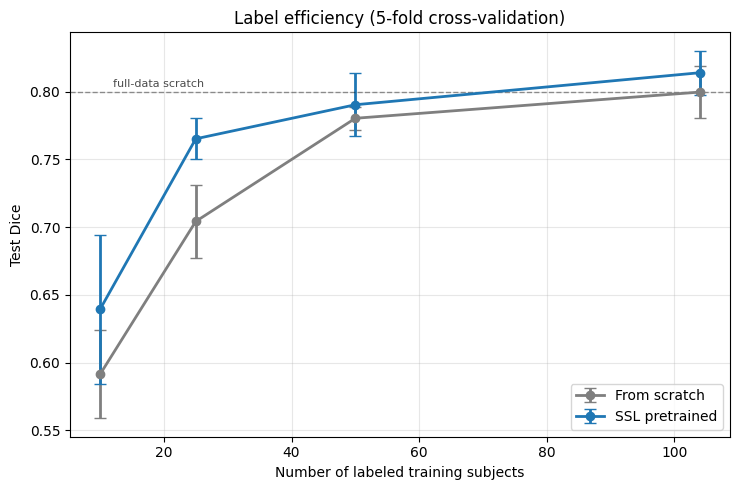


% of full-data scratch performance (0.7997):
  SSL @ n= 10: 0.6393  = 79.9%
  SSL @ n= 25: 0.7652  = 95.7%
  SSL @ n= 50: 0.7904  = 98.8%
  SSL @ n=104: 0.8140  = 101.8%


In [ ]:
dfe = pd.DataFrame([{'n_labeled': r['n_labeled'], 'pretrained': r['pretrained'],
                     'fold': r['fold'], 'dice': r['test_mean_dice']} for r in ssl_results])
piv = dfe.groupby(['n_labeled','pretrained'])['dice'].agg(['mean','std','count']).reset_index()
piv.to_csv(os.path.join(SSL_DIR, 'label_efficiency.csv'), index=False)
print(piv.to_string(index=False))

# full-data scratch reference line
full_scratch = piv[(piv.pretrained==False) & (piv.n_labeled==piv.n_labeled.max())]['mean'].iloc[0]

fig, ax = plt.subplots(figsize=(7.5,5))
for pre, lbl, c in [(False,'From scratch','tab:gray'), (True,'SSL pretrained','tab:blue')]:
    s = piv[piv.pretrained == pre].sort_values('n_labeled')
    ax.errorbar(s['n_labeled'], s['mean'], yerr=s['std'], marker='o',
                capsize=4, label=lbl, color=c, lw=2)
ax.axhline(full_scratch, ls='--', c='k', alpha=.4, lw=1)
ax.text(12, full_scratch+0.004, 'full-data scratch', fontsize=8, alpha=.7)
ax.set_xlabel('Number of labeled training subjects')
ax.set_ylabel('Test Dice')
ax.set_title(f'Label efficiency ({N_FOLDS_USED}-fold cross-validation)')
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(SSL_DIR, 'label_efficiency.png'), dpi=200)
plt.show()

print(f"\n% of full-data scratch performance ({full_scratch:.4f}):")
for _, r in piv[piv.pretrained==True].sort_values('n_labeled').iterrows():
    print(f"  SSL @ n={int(r['n_labeled']):3d}: {r['mean']:.4f}  = {100*r['mean']/full_scratch:.1f}%")

In [ ]:
from scipy import stats

print(f"Paired comparison, SSL vs scratch ({N_FOLDS_USED} folds):\n")
print(f"{'n':>5} {'SSL':>8} {'scratch':>8} {'diff':>8} {'95% CI':>18} {'t-test p':>9} {'Wilcox p':>9}")
for n_lab in sorted(dfe.n_labeled.unique()):
    a = dfe[(dfe.n_labeled==n_lab) & (dfe.pretrained==True)].sort_values('fold')['dice'].values
    b = dfe[(dfe.n_labeled==n_lab) & (dfe.pretrained==False)].sort_values('fold')['dice'].values
    if len(a) != len(b) or len(a) < 3:
        continue
    d = a - b
    t, p_t = stats.ttest_rel(a, b)
    try:
        _, p_w = stats.wilcoxon(a, b)
    except ValueError:
        p_w = np.nan
    ci = stats.t.interval(0.95, len(d)-1, loc=d.mean(), scale=stats.sem(d)) if d.std() > 0 else (d.mean(), d.mean())
    print(f"{int(n_lab):5d} {a.mean():8.4f} {b.mean():8.4f} {d.mean():+8.4f} "
          f"[{ci[0]:+.4f},{ci[1]:+.4f}] {p_t:9.4f} {p_w:9.4f}")

print("\nCohen's d (paired):")
for n_lab in sorted(dfe.n_labeled.unique()):
    a = dfe[(dfe.n_labeled==n_lab) & (dfe.pretrained==True)].sort_values('fold')['dice'].values
    b = dfe[(dfe.n_labeled==n_lab) & (dfe.pretrained==False)].sort_values('fold')['dice'].values
    if len(a) == len(b) and len(a) >= 3 and (a-b).std() > 0:
        print(f"  n={int(n_lab):3d}: d = {(a-b).mean()/(a-b).std(ddof=1):.2f}")

Paired comparison, SSL vs scratch (5 folds):

    n      SSL  scratch     diff             95% CI  t-test p  Wilcox p
   10   0.6393   0.5914  +0.0480 [+0.0198,+0.0762]    0.0092    0.0625
   25   0.7652   0.7043  +0.0610 [+0.0416,+0.0803]    0.0009    0.0625
   50   0.7904   0.7804  +0.0100 [-0.0165,+0.0365]    0.3550    0.4375
  104   0.8140   0.7997  +0.0143 [+0.0034,+0.0252]    0.0221    0.0625

Cohen's d (paired):
  n= 10: d = 2.11
  n= 25: d = 3.91
  n= 50: d = 0.47
  n=104: d = 1.62


In [ ]:
TARGET_N = 25

ssl_pc, scr_pc = [], []
for f in folds[:N_FOLDS_USED]:
    k = f['fold']
    for pre, store in [(True, ssl_pc), (False, scr_pc)]:
        p = os.path.join(SSL_DIR, f"results_fold{k}_{'ssl' if pre else 'scratch'}_n{TARGET_N}.json")
        if os.path.exists(p):
            store.append(json.load(open(p))['per_class_dice'])

ssl_pc, scr_pc = np.array(ssl_pc), np.array(scr_pc)
print(f"regions compared over {len(ssl_pc)} folds at n={TARGET_N}\n")

# structure size, to test whether SSL helps small structures more
vox = np.zeros(NUM_CLASSES)
for d in all_files[:25]:
    lb = nib.load(d['label']).get_fdata()
    u, c = np.unique(lb, return_counts=True)
    for v, n in zip(u, c):
        v = int(v)
        if v < 256 and _LUT[v] > 0:
            vox[_LUT[v]] += n
vox_frac = vox[1:] / vox[1:].sum()

reg = pd.DataFrame({
    'region':   [CLASS_NAMES[i+1] for i in range(ssl_pc.shape[1])],
    'ssl':      np.round(ssl_pc.mean(0), 4),
    'scratch':  np.round(scr_pc.mean(0), 4),
    'gain':     np.round(ssl_pc.mean(0) - scr_pc.mean(0), 4),
    'size_pct': np.round(100*vox_frac[:ssl_pc.shape[1]], 3),
}).sort_values('gain', ascending=False)
reg.to_csv(os.path.join(SSL_DIR, f'per_region_gain_n{TARGET_N}.csv'), index=False)
print(reg.to_string(index=False))

# does SSL help small structures disproportionately?
rho, p_rho = stats.spearmanr(reg['size_pct'], reg['gain'])
print(f"\nSpearman(structure size, SSL gain) = {rho:.3f}  (p={p_rho:.3f})")
print("negative rho => SSL helps SMALLER structures more")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
o = reg.sort_values('gain')
ax[0].barh(range(len(o)), o['gain'], color=np.where(o['gain']>0, 'tab:blue', 'tab:red'))
ax[0].set_yticks(range(len(o))); ax[0].set_yticklabels(o['region'], fontsize=7)
ax[0].axvline(0, c='k', lw=.8)
ax[0].set_xlabel('Dice gain from SSL'); ax[0].set_title(f'Per-region SSL gain (n={TARGET_N})')
ax[1].scatter(reg['size_pct'], reg['gain'], alpha=.75)
ax[1].set_xscale('log'); ax[1].axhline(0, c='k', lw=.8)
ax[1].set_xlabel('Structure size (% of labeled voxels, log scale)')
ax[1].set_ylabel('Dice gain from SSL')
ax[1].set_title(f'SSL gain vs. structure size (rho={rho:.2f})')
ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(SSL_DIR, f'per_region_gain_n{TARGET_N}.png'), dpi=200)
plt.show()